<a href="https://colab.research.google.com/github/varsityboi/speech-emotion-recognition/blob/main/05_transfer_wavlm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import glob, os, numpy as np, pandas as pd, librosa, kagglehub
from tqdm.auto import tqdm

PROJECT_DIR = "/content/drive/MyDrive/SER_Project"
SR, CLIP_S = 16000, 3.5
N_SAMPLES = int(SR * CLIP_S)          # 56,000 numbers per clip

# find the audio files again
crema_root = kagglehub.dataset_download("ejlok1/cremad")
ravdess_root = kagglehub.dataset_download("uwrfkaggler/ravdess-emotional-speech-audio")
all_wavs = (glob.glob(os.path.join(crema_root, "**", "*.wav"), recursive=True) +
            glob.glob(os.path.join(ravdess_root, "**", "*.wav"), recursive=True))
path_of = {os.path.basename(p): p for p in all_wavs}

data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")
data["path"] = data["file"].map(path_of)
print("Files found:", data["path"].notna().sum(), "of", len(data))

def clean_audio_noscale(path):
    y, _ = librosa.load(path, sr=SR, mono=True)        # 16 kHz, mono
    y, _ = librosa.effects.trim(y, top_db=30)           # cut silence at the edges
    if len(y) >= N_SAMPLES:                             # too long → keep the middle 3.5s
        s = (len(y) - N_SAMPLES) // 2
        y = y[s:s + N_SAMPLES]
    else:                                               # too short → pad with silence
        y = np.pad(y, (0, N_SAMPLES - len(y)))
    return y

W = np.zeros((len(data), N_SAMPLES), dtype=np.float16)
for i, p in enumerate(tqdm(data["path"], desc="Waveforms")):
    W[i] = clean_audio_noscale(p)

np.save(f"{PROJECT_DIR}/waveforms_noscale.npy", W)
print("Saved:", W.shape, "| size:", round(W.nbytes / 1e9, 2), "GB")

Mounted at /content/drive


100%|██████████| 451M/451M [00:05<00:00, 89.8MB/s]

Extracting files...


Using Colab cache for faster access to the 'ravdess-emotional-speech-audio' dataset.
Files found: 8498 of 8498


Waveforms:   0%|          | 0/8498 [00:00<?, ?it/s]

Saved: (8498, 56000) | size: 0.95 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, torch
PROJECT_DIR = "/content/drive/MyDrive/SER_Project"
print("GPU:", torch.cuda.is_available())

Mounted at /content/drive
GPU: True


In [ ]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import WavLMModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad"]
W = np.load(f"{PROJECT_DIR}/waveforms_noscale.npy")
data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")

# ---------- data ----------
class WaveDataset(Dataset):
    def __init__(self, split):
        self.idx = np.where(data["split"] == split)[0]
        self.y = data["label"].values[self.idx]
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        x = torch.from_numpy(W[self.idx[i]].astype(np.float32))
        return x, int(self.y[i])

loaders = {s: DataLoader(WaveDataset(s), batch_size=8, shuffle=(s == "train"),
                         num_workers=2, pin_memory=True)
           for s in ["train", "val", "test", "ravdess_test"]}
print({s: len(l.dataset) for s, l in loaders.items()})

# ---------- model ----------
class WavLMClassifier(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()
        self.wavlm = WavLMModel.from_pretrained("microsoft/wavlm-base-plus", layerdrop=0.0)
        self.wavlm.freeze_feature_encoder()
        n_layers = self.wavlm.config.num_hidden_layers + 1          # 13
        hidden = self.wavlm.config.hidden_size                      # 768
        self.layer_weights = nn.Parameter(torch.zeros(n_layers))
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(hidden, 256), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(256, n_classes))

    def forward(self, wav):
        out = self.wavlm(wav, output_hidden_states=True)
        hs = torch.stack(out.hidden_states, dim=0)                  # (13, batch, time, 768)
        w = torch.softmax(self.layer_weights, dim=0)
        x = (w[:, None, None, None] * hs).sum(dim=0)                # mix of 13 layers
        x = x.mean(dim=1)                                           # average over time
        return self.head(x)                                         # 6 emotion scores

model = WavLMClassifier().to(device)
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Params: total {total/1e6:.1f}M | trainable {trainable/1e6:.1f}M")

# ---------- quick test: eval mode AND train mode ----------
xb, yb = next(iter(loaders["val"]))
with torch.no_grad():
    out_eval = model.eval()(xb.to(device))
    out_train = model.train()(xb.to(device))
print("Eval:", tuple(out_eval.shape), "| Train:", tuple(out_train.shape))

Device: cuda
{'train': 5329, 'val': 1065, 'test': 1048, 'ravdess_test': 1056}


config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Params: total 94.6M | trainable 90.4M
Eval: (8, 6) | Train: (8, 6)


Epoch 1/10:   0%|          | 0/667 [00:00<?, ?it/s]

Epoch 1: train acc 37.6% | val acc 42.2% | val loss 1.413 | 114s  ← best, saved


Epoch 2/10:   0%|          | 0/667 [00:00<?, ?it/s]

Epoch 2: train acc 63.7% | val acc 59.2% | val loss 1.345 | 114s  ← best, saved


Epoch 3/10:   0%|          | 0/667 [00:00<?, ?it/s]

Epoch 3: train acc 76.9% | val acc 63.8% | val loss 1.114 | 116s  ← best, saved


... (10 outputs left out)

Epoch 9/10:   0%|          | 0/667 [00:00<?, ?it/s]

Epoch 9: train acc 96.2% | val acc 69.5% | val loss 1.956 | 117s


Epoch 10/10:   0%|          | 0/667 [00:00<?, ?it/s]

Epoch 10: train acc 97.4% | val acc 70.5% | val loss 1.990 | 114s
{'model': 'wavlm_noscale', 'best_epoch': 8, 'val_acc': 71.74, 'ravdess_acc': 59.56, 'layer_weights': [0.064, 0.062, 0.063, 0.062, 0.063, 0.065, 0.077, 0.109, 0.108, 0.096, 0.087, 0.08, 0.063]}


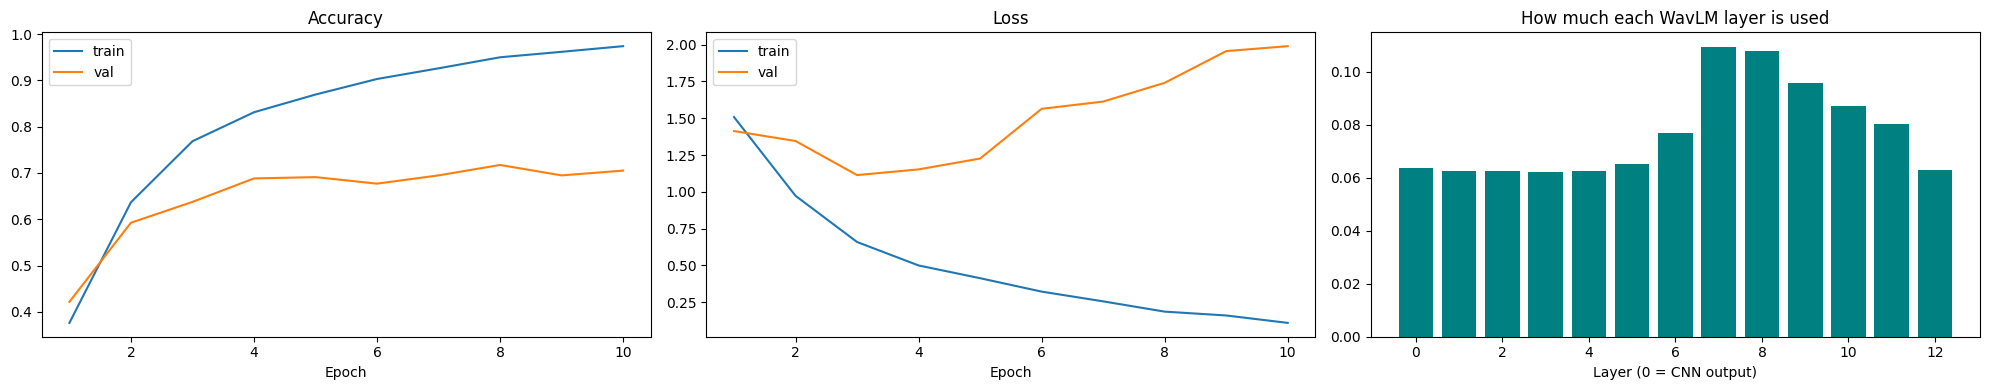

All saved to /content/drive/MyDrive/SER_Project


In [ ]:
import time, json, os
from tqdm.auto import tqdm
from transformers import get_linear_schedule_with_warmup
import matplotlib.pyplot as plt

EPOCHS, PATIENCE = 10, 3
name = "wavlm_noscale"
MODEL_DIR, LOG_DIR, FIG_DIR = (f"{PROJECT_DIR}/{d}" for d in ["models", "logs", "figures"])
for d in [MODEL_DIR, LOG_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

# ---------- how it learns ----------
wavlm_params = [p for p in model.wavlm.parameters() if p.requires_grad]
new_params = list(model.head.parameters()) + [model.layer_weights]
optimizer = torch.optim.AdamW([{"params": wavlm_params, "lr": 3e-5},    # pretrained part: tiny steps
                               {"params": new_params,   "lr": 1e-3}],   # new parts: normal steps
                              weight_decay=0.01)
total_steps = EPOCHS * len(loaders["train"])
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda")
loss_fn = nn.CrossEntropyLoss()

def evaluate(loader):
    model.eval()
    correct = total = 0; loss_sum = 0.0
    with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.float16):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += loss_fn(logits.float(), yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item(); total += len(yb)
    return loss_sum / total, correct / total

# ---------- training loop ----------
history, best_val, bad = [], 0.0, 0
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time()
    correct = total = 0; loss_sum = 0.0
    for xb, yb in tqdm(loaders["train"], desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            logits = model(xb)
            loss = loss_fn(logits.float(), yb)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        loss_sum += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item(); total += len(yb)

    val_loss, val_acc = evaluate(loaders["val"])
    row = {"epoch": epoch, "loss": loss_sum / total, "accuracy": correct / total,
           "val_loss": val_loss, "val_accuracy": val_acc}
    history.append(row)
    pd.DataFrame(history).to_csv(f"{LOG_DIR}/{name}_history.csv", index=False)

    msg = (f"Epoch {epoch}: train acc {row['accuracy']*100:.1f}% | val acc {val_acc*100:.1f}% "
           f"| val loss {val_loss:.3f} | {time.time()-t0:.0f}s")
    if val_acc > best_val:
        best_val, bad = val_acc, 0
        torch.save(model.state_dict(), f"{MODEL_DIR}/{name}_best.pt")
        msg += "  ← best, saved"
    else:
        bad += 1
    print(msg)
    if bad >= PATIENCE:
        print(f"Early stopping: no improvement for {PATIENCE} epochs")
        break

# ---------- results ----------
model.load_state_dict(torch.load(f"{MODEL_DIR}/{name}_best.pt"))
_, val_acc = evaluate(loaders["val"])
_, rav_acc = evaluate(loaders["ravdess_test"])
layer_mix = torch.softmax(model.layer_weights, 0).detach().cpu().numpy()
best_epoch = int(np.argmax([r["val_accuracy"] for r in history])) + 1
result = {"model": name, "best_epoch": best_epoch,
          "val_acc": round(val_acc * 100, 2), "ravdess_acc": round(rav_acc * 100, 2),
          "layer_weights": [round(float(w), 3) for w in layer_mix]}
json.dump(result, open(f"{LOG_DIR}/{name}_result.json", "w"), indent=2)
print(result)

h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
axes[0].plot(h["epoch"], h["accuracy"], label="train"); axes[0].plot(h["epoch"], h["val_accuracy"], label="val")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h["epoch"], h["loss"], label="train"); axes[1].plot(h["epoch"], h["val_loss"], label="val")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
axes[2].bar(range(len(layer_mix)), layer_mix, color="teal")
axes[2].set_title("How much each WavLM layer is used"); axes[2].set_xlabel("Layer (0 = CNN output)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}_curves.png", dpi=150); plt.show()
print("All saved to", PROJECT_DIR)

 epoch   loss  accuracy  val_loss  val_accuracy
     1 1.5082    0.3761    1.4130        0.4216
     2 0.9730    0.6367    1.3453        0.5925
     3 0.6589    0.7686    1.1138        0.6376
     4 0.4995    0.8313    1.1524        0.6883
     5 0.4129    0.8696    1.2262        0.6911
     6 0.3217    0.9032    1.5642        0.6770
     7 0.2555    0.9263    1.6133        0.6948
     8 0.1857    0.9501    1.7409        0.7174
     9 0.1595    0.9619    1.9564        0.6948
    10 0.1091    0.9741    1.9900        0.7052

Best epoch: 8
Val accuracy: 71.74 %
RAVDESS accuracy: 59.56 %
Layer weights: [0.064, 0.062, 0.063, 0.062, 0.063, 0.065, 0.077, 0.109, 0.108, 0.096, 0.087, 0.08, 0.063]


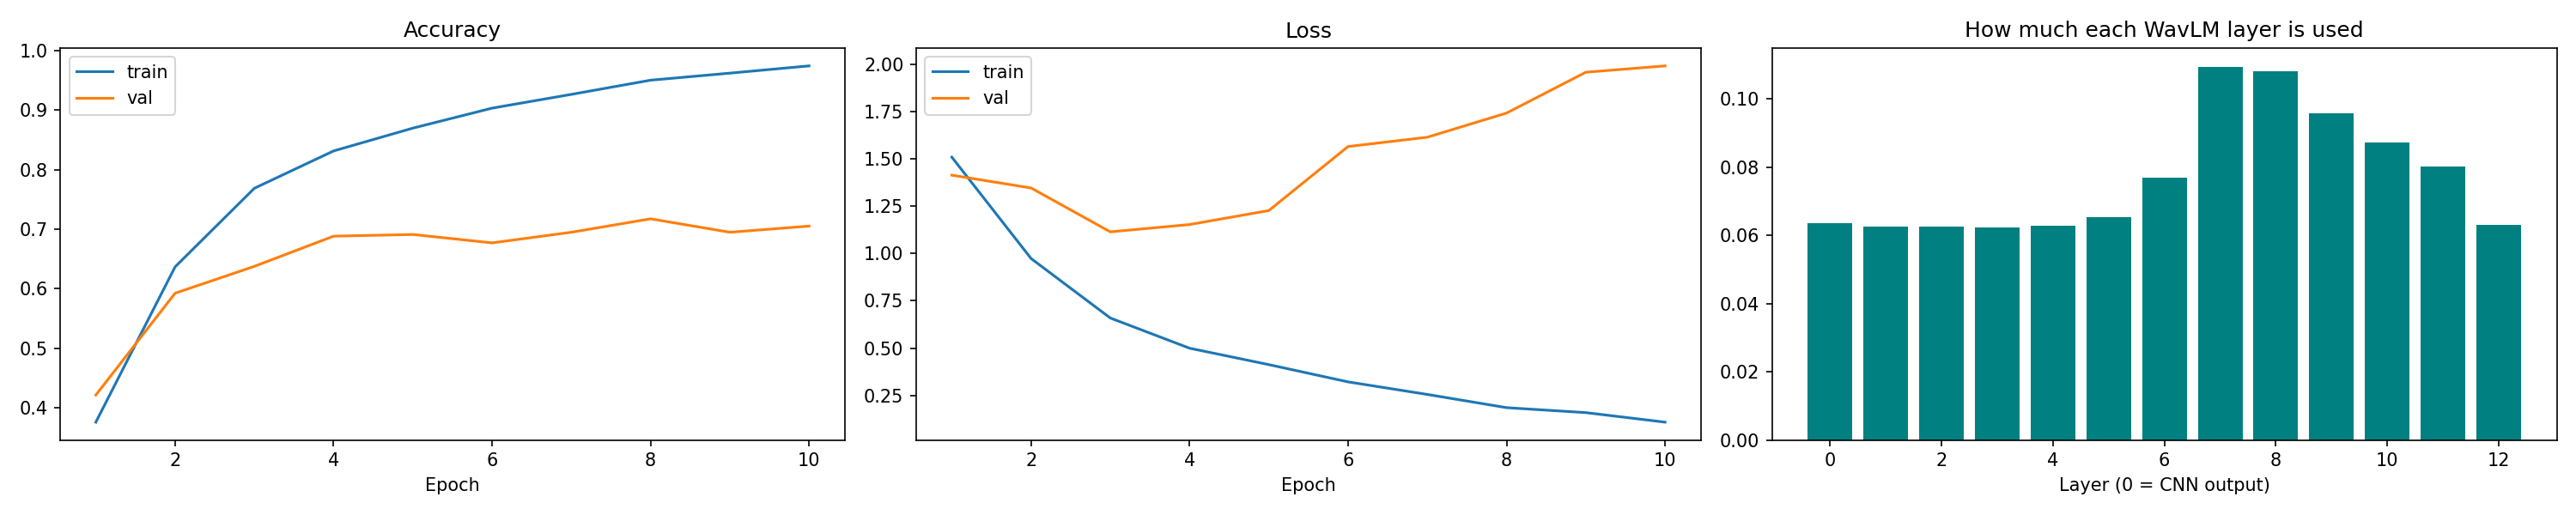

In [ ]:
import json, pandas as pd
from IPython.display import Image, display

name = "wavlm_noscale"
LOG_DIR, FIG_DIR = f"{PROJECT_DIR}/logs", f"{PROJECT_DIR}/figures"

# 1. every epoch
print(pd.read_csv(f"{LOG_DIR}/{name}_history.csv").round(4).to_string(index=False))

# 2. final scores
result = json.load(open(f"{LOG_DIR}/{name}_result.json"))
print("\nBest epoch:", result["best_epoch"])
print("Val accuracy:", result["val_acc"], "%")
print("RAVDESS accuracy:", result["ravdess_acc"], "%")
print("Layer weights:", result["layer_weights"])

# 3. the graphs
display(Image(f"{FIG_DIR}/{name}_curves.png"))